# Coefficient estimation for one AR(p) process

Choose **`p` in the settings cell**, then run the notebook from top to bottom. It generates one coefficient vector and one simulated path, finds a direction of small empirical width in dimension **k = p + 1**, prints that direction, and only then transforms it into coefficient estimates in a separate cell.

The search uses the same method as [ar3_minimum_width_k4.ipynb](../ar3_minimum_width_k4.ipynb), section **Four-method coefficient comparison for known AR order**. The editable settings cell controls the number of starts, iteration budget, step scale, and geometric decay. Here, only the chosen embedding is optimized.

The reported minimizing direction is the **best direction found by the numerical search**. The notebook does not certify a global minimum.

In [1]:
import sys
from importlib import reload
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.spatial.distance import pdist
from threadpoolctl import threadpool_limits

AR_CODE_DIR = next(
    (
        candidate.resolve()
        for root in (Path.cwd(), *Path.cwd().parents)
        for candidate in (root / "Code" / "Code_AR_processes", root)
        if (candidate / "ar_tools/functions.py").is_file()
    ),
    None,
)
if AR_CODE_DIR is None:
    raise FileNotFoundError("Could not locate Code/Code_AR_processes.")
PROJECT_ROOT = AR_CODE_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Pick up shared optimizer updates when rerunning an existing notebook kernel.
from Code.Code_AR_processes.ar_tools import descent as descent_tools
reload(descent_tools)
from Code.Code_AR_processes.ar_tools.descent import projected_subgradient_empirical_width
from Code.Code_AR_processes.ar_tools.functions import (
    coefficients_from_minimizing_direction,
    is_stationary,
    jones_ar_coefficients,
    simulate_uniform_ar,
    sliding_window_point_cloud,
)

np.set_printoptions(precision=8, suppress=True)

## 1. Choose the process order and descent settings

Change `p` to the positive integer order you want. The coefficients are drawn automatically using the existing `jones_ar_coefficients` helper. The seeds make each run reproducible; change `coefficient_seed` or `process_seed` to generate a different process.

Implementation: [ar_tools/functions.py](../ar_tools/functions.py), functions `jones_ar_coefficients` and `simulate_uniform_ar`.

In [2]:
p = 3                         # CHANGE THIS: desired AR order.
sample_size = 2_000            # Number of retained observations.
burnin = 1_000
innovation_half_width = 1.0    # Innovations are uniform on [-1, 1] by default.

coefficient_seed = 20260910
process_seed = 20260911
optimizer_seed = 20260912

number_of_starts = 12
optimization_iterations = 10_000
initial_step_scale = 0.2
geometric_decay = 0.997
improvement_tolerance = 1e-10
patience = 200                 # Consecutive evaluations without sufficient improvement.

# Validate editable settings before simulating or optimizing.
for name, value, lower_bound in (
    ("p", p, 1),
    ("sample_size", sample_size, 1),
    ("burnin", burnin, 0),
    ("number_of_starts", number_of_starts, 1),
    ("optimization_iterations", optimization_iterations, 1),
    ("patience", patience, 1),
):
    if (
        isinstance(value, (bool, np.bool_))
        or not isinstance(value, (int, np.integer))
        or value < lower_bound
    ):
        raise ValueError(f"{name} must be an integer at least {lower_bound}.")
if sample_size < p + 2:
    raise ValueError("sample_size must be at least p + 2 to form two embedding points.")
for name, value in (
    ("innovation_half_width", innovation_half_width),
    ("initial_step_scale", initial_step_scale),
):
    if not np.isfinite(value) or value <= 0:
        raise ValueError(f"{name} must be positive and finite.")
if not np.isfinite(geometric_decay) or not 0 < geometric_decay < 1:
    raise ValueError("geometric_decay must lie strictly between zero and one.")
if not np.isfinite(improvement_tolerance) or improvement_tolerance < 0:
    raise ValueError("improvement_tolerance must be finite and nonnegative.")

embedding_dimension = p + 1

## 2. Generate one AR(p) process

The simulation uses the sign convention

$$X_t=\sum_{j=1}^p\phi_j X_{t-j}+\varepsilon_t,$$

with zero intercept. The printed true coefficients are used for comparison after fitting. They are not passed to the direction optimizer.

Implementation: [ar_tools/functions.py](../ar_tools/functions.py), functions `jones_ar_coefficients`, `is_stationary`, and `simulate_uniform_ar`.

In [3]:
true_phi = jones_ar_coefficients(p, rng=coefficient_seed)
stationary, companion_eigenvalues = is_stationary(true_phi)
if not stationary:
    raise RuntimeError("The generated coefficients did not pass the stationarity check.")

series = simulate_uniform_ar(
    true_phi,
    sample_size=sample_size,
    burnin=burnin,
    half_width=innovation_half_width,
    rng=process_seed,
)
if not np.all(np.isfinite(series)):
    raise RuntimeError("The simulated path contains nonfinite values.")

point_cloud = sliding_window_point_cloud(series, embedding_dimension)
point_cloud_diameter = float(pdist(point_cloud).max())
if not np.isfinite(point_cloud_diameter) or point_cloud_diameter <= 0:
    raise RuntimeError("Cannot normalize the step: the point-cloud diameter is invalid.")
initial_step = initial_step_scale / point_cloud_diameter

print(f"Generated one AR({p}) process")
print(f"True coefficients phi = {true_phi}")
print(f"Retained observations = {len(series)}; burn-in = {burnin}")
print(f"Embedding dimension k = {embedding_dimension}")
print(f"Point-cloud shape = {point_cloud.shape}")
print(f"Point-cloud diameter L_T = {point_cloud_diameter:.10f}")
print(f"Initial step eta_0 = {initial_step:.10g}")

Generated one AR(3) process
True coefficients phi = [-1.0201964  -0.40421235 -0.37447885]
Retained observations = 2000; burn-in = 1000
Embedding dimension k = 4
Point-cloud shape = (1997, 4)
Point-cloud diameter L_T = 36.5616732486
Initial step eta_0 = 0.005470209162


## 3. Find and output the minimizing direction

The newest-first embedding points are $Y_t=(X_t,X_{t-1},\ldots,X_{t-p})$. The search minimizes

$$\widehat w(u)=\max_t Y_t^\top u-\min_t Y_t^\top u,
\qquad \|u\|_2=1.$$

For each start, the shared optimizer uses

$$g_m=Y_{\max,m}-Y_{\min,m},\qquad
\xi_m=g_m-(u_m^\top g_m)u_m,$$

$$\eta_m=\frac{\texttt{initial\_step\_scale}}{L_T}
\texttt{geometric\_decay}^{\,m},\qquad
u_{m+1}=\frac{u_m-\eta_m\xi_m}{\|u_m-\eta_m\xi_m\|_2},\quad m=0,1,\ldots.$$

All starts are normalized Gaussian draws. Each start retains its best recorded direction, using the configured improvement tolerance. Each start stops after the configured number of consecutive iterations without sufficient improvement, or when its iteration budget is reached. Set `patience` and `improvement_tolerance` in the settings cell. The smallest recorded width across starts is selected. Its sign is chosen so that $\widehat u_0\geq 0$, without consulting the true coefficients.

Implementation: [ar_tools/descent.py](../ar_tools/descent.py), function `projected_subgradient_empirical_width`; embedding coordinate order: [ar_tools/functions.py](../ar_tools/functions.py), function `sliding_window_point_cloud`.

In [4]:
# Refresh the optimizer here as well, so this cell can be rerun on its own.
from importlib import reload
from Code.Code_AR_processes.ar_tools import descent as descent_tools
reload(descent_tools)
from Code.Code_AR_processes.ar_tools.descent import projected_subgradient_empirical_width

initial_generator = np.random.default_rng(
    np.random.SeedSequence([optimizer_seed, 0, embedding_dimension, 20])
)
initial_directions = initial_generator.normal(
    size=(number_of_starts, embedding_dimension)
)
initial_directions /= np.linalg.norm(initial_directions, axis=1, keepdims=True)

optimization_start = perf_counter()
with threadpool_limits(limits=1):
    descent_results = [
        projected_subgradient_empirical_width(
            points=point_cloud,
            iterations=optimization_iterations,
            initial_step=initial_step,
            patience=patience,
            improvement_tolerance=improvement_tolerance,
            rng=np.random.SeedSequence([
                optimizer_seed, 0, embedding_dimension, 21, start_index,
            ]),
            initial_direction=initial_direction,
            step_schedule="geometric",
            geometric_decay=geometric_decay,
        )
        for start_index, initial_direction in enumerate(initial_directions)
    ]
optimization_seconds = perf_counter() - optimization_start

start_widths = np.array([result["minimum_width"] for result in descent_results])
best_start_index = int(np.argmin(start_widths))
best_result = descent_results[best_start_index]
minimizing_direction = best_result["direction"].copy()
if minimizing_direction[0] < 0:
    minimizing_direction *= -1
minimum_width = float(best_result["minimum_width"])

if not np.all(np.isfinite(minimizing_direction)):
    raise RuntimeError("The selected direction contains nonfinite values.")
if not np.isclose(np.linalg.norm(minimizing_direction), 1.0):
    raise RuntimeError("The selected direction is not a unit vector.")
if not np.isclose(np.ptp(point_cloud @ minimizing_direction), minimum_width):
    raise RuntimeError("The selected direction does not reproduce the reported width.")

print(f"Best start = {best_start_index + 1} of {number_of_starts}")
print(f"Smallest empirical width found = {minimum_width:.10f}")
print("Minimizing unit direction u_hat (coordinates u_0, u_1, ..., u_p):")
print(minimizing_direction)
print(f"Norm of u_hat = {np.linalg.norm(minimizing_direction):.10f}")
print(f"First coordinate u_hat_0 = {minimizing_direction[0]:.10f}")
print(f"Optimization time = {optimization_seconds:.3f} seconds")

start_summary = pd.DataFrame({
    "start": np.arange(1, number_of_starts + 1),
    "best_width": start_widths,
    "iterations_evaluated": [len(result["width_history"]) for result in descent_results],
    "termination_reason": [result["termination_reason"] for result in descent_results],
    "selected": np.arange(number_of_starts) == best_start_index,
})
display(start_summary)

Best start = 3 of 12
Smallest empirical width found = 1.3055352045
Minimizing unit direction u_hat (coordinates u_0, u_1, ..., u_p):
[0.64637305 0.66248553 0.2788784  0.25601101]
Norm of u_hat = 1.0000000000
First coordinate u_hat_0 = 0.6463730489
Optimization time = 1.282 seconds


,start,best_width,iterations_evaluated,termination_reason,selected
0,1,1.323055,7351,patience,False
1,2,1.307361,7022,patience,False
2,3,1.305535,6537,patience,True
3,4,1.477141,7857,patience,False
4,5,1.852143,201,patience,False
5,6,1.307234,7034,patience,False
6,7,1.598704,7481,patience,False
7,8,1.760432,251,patience,False
8,9,1.307563,7168,patience,False
9,10,1.308488,7140,patience,False


## 3a. Inspect every start across iterations

Each panel shows one start: **blue is the current empirical width**, and **orange is the best width recorded so far**. The selected start is highlighted. The panel titles give the best width and the number of evaluated iterations.

The first figure shows the full run for every start. The second zooms into the **last 1,000 iterations** of each run, so late changes are visible. If a run has fewer than 1,000 iterations, its complete trace is shown in both figures. Each panel uses its own vertical scale.

These figures use the existing `descent_results`; running the plotting cell alone does not rerun descent. Both figures are displayed below and automatically saved as PDF and PNG under `outputs/pdfs/ar_single_process_coefficient_estimation/` and `outputs/images/ar_single_process_coefficient_estimation/`.

Trace implementation: [ar_tools/descent.py](../ar_tools/descent.py), `projected_subgradient_empirical_width` (the `width_history` and `best_width_history` arrays).

All iterations: PDF saved to /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar_single_process_coefficient_estimation/descent_starts_all_iterations.pdf


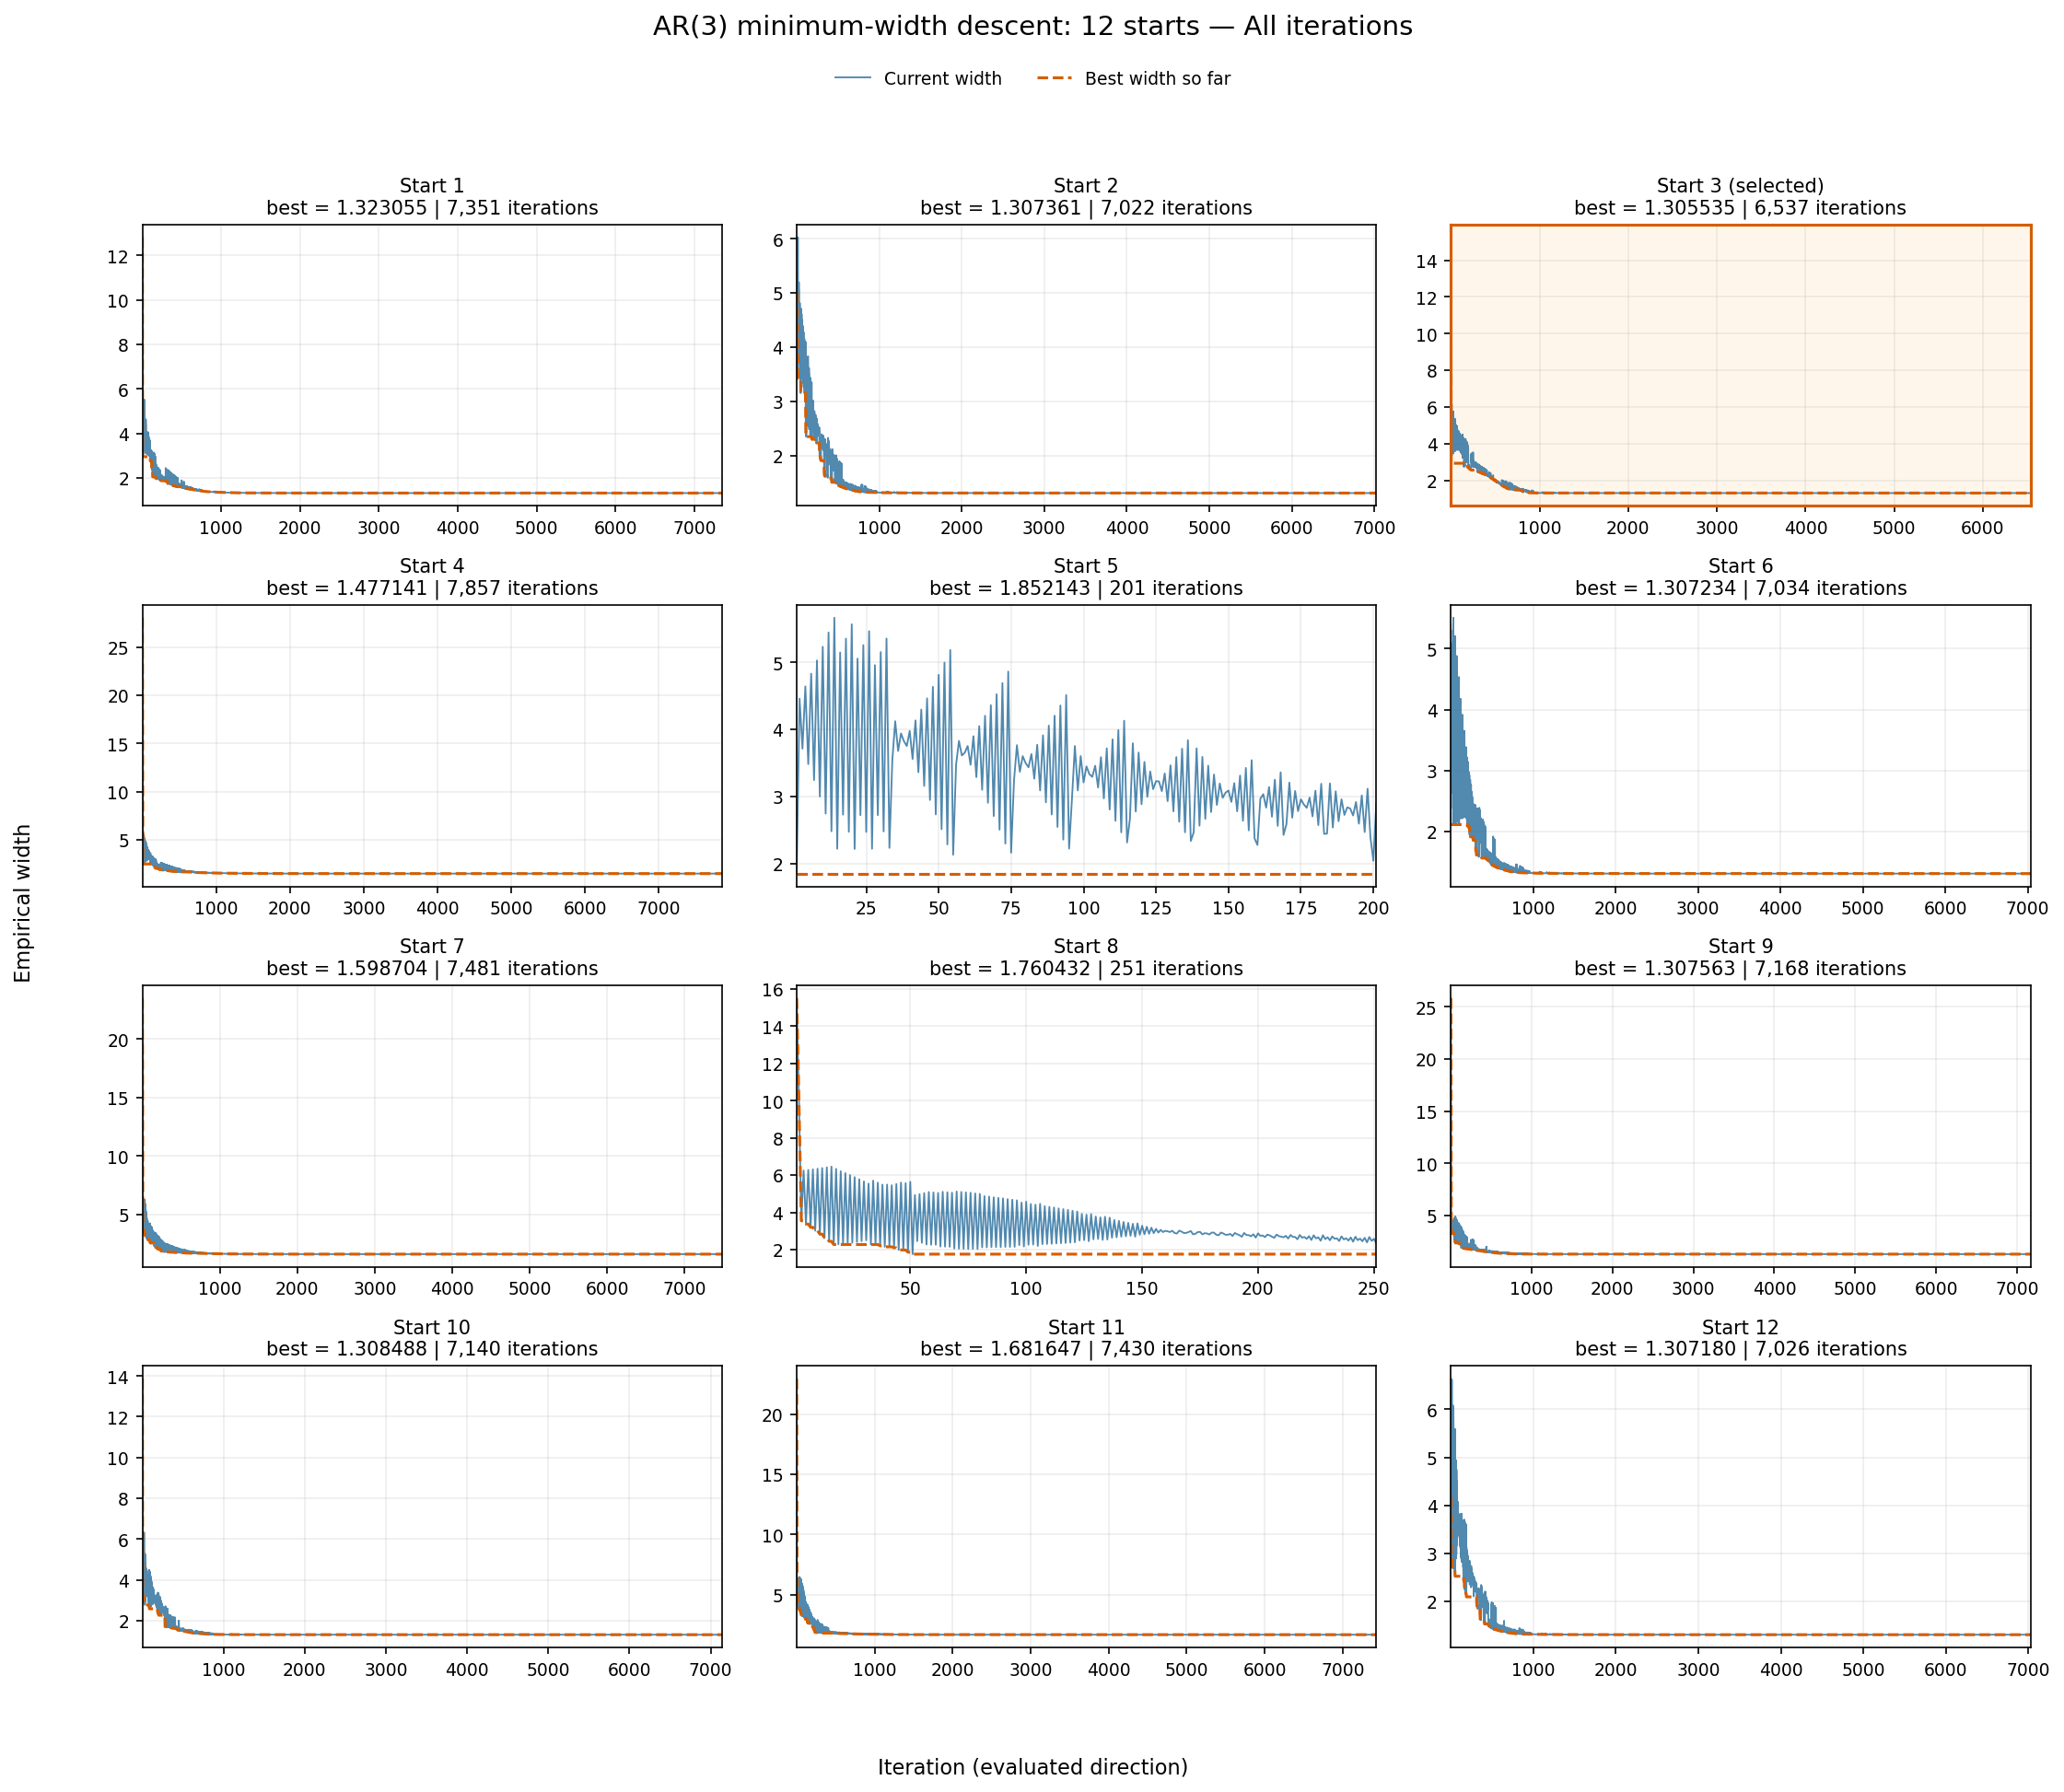

Last 1,000 iterations of each start: PDF saved to /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar_single_process_coefficient_estimation/descent_starts_last_1000_iterations.pdf


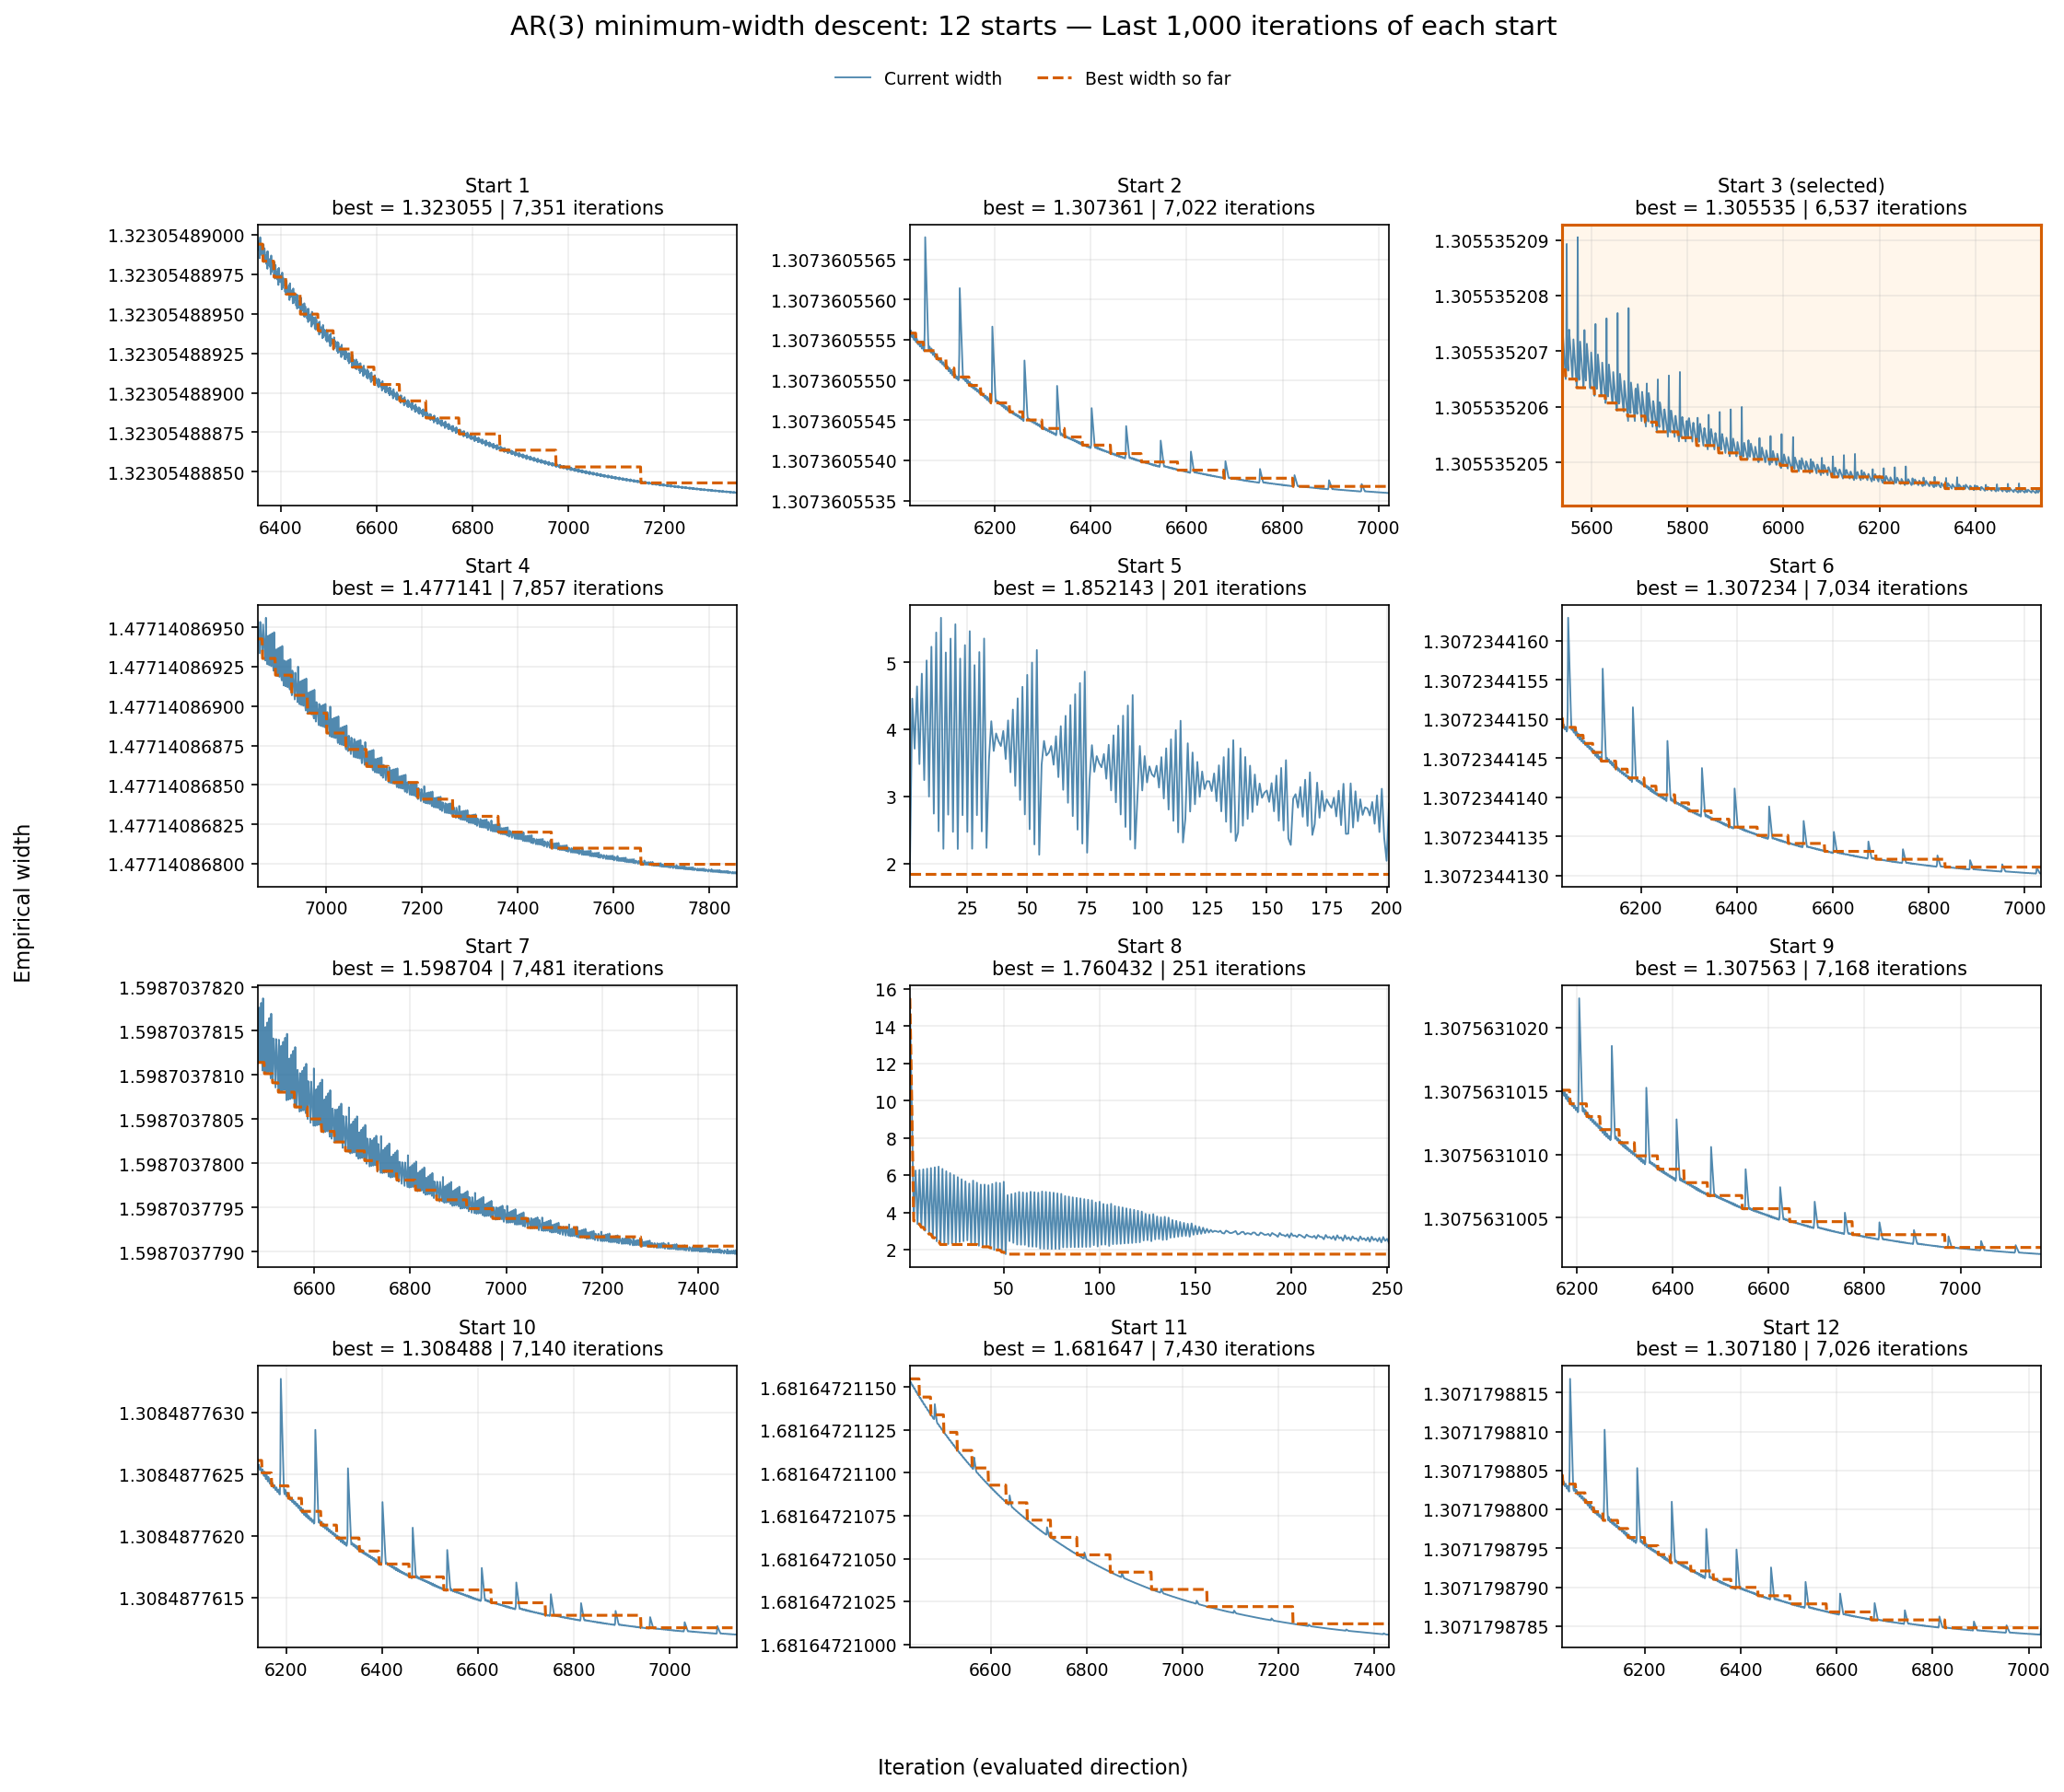

In [5]:
PDF_DIR = AR_CODE_DIR / "outputs" / "pdfs" / "ar_single_process_coefficient_estimation"
IMAGE_DIR = AR_CODE_DIR / "outputs" / "images" / "ar_single_process_coefficient_estimation"
PDF_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

plotted_start_count = len(descent_results)
plot_columns = min(3, plotted_start_count)
plot_rows = (plotted_start_count + plot_columns - 1) // plot_columns
iteration_plot_paths = []

for view_name, tail_iterations, view_title in (
    ("all_iterations", None, "All iterations"),
    ("last_1000_iterations", 1_000, "Last 1,000 iterations of each start"),
):
    with plt.rc_context({"font.size": 9, "pdf.fonttype": 42}):
        fig, axes = plt.subplots(
            plot_rows,
            plot_columns,
            figsize=(5.0 * plot_columns, 3.0 * plot_rows + 1.0),
            squeeze=False,
        )
        for start_index, (ax, result) in enumerate(zip(axes.flat, descent_results)):
            current_widths = np.asarray(result["width_history"])
            best_widths = np.asarray(result["best_width_history"])
            first_index = (
                0 if tail_iterations is None
                else max(0, len(current_widths) - tail_iterations)
            )
            shown_iterations = np.arange(first_index + 1, len(current_widths) + 1)
            ax.plot(
                shown_iterations,
                current_widths[first_index:],
                color="#3274A1",
                linewidth=0.9,
                alpha=0.85,
                label="Current width",
            )
            ax.plot(
                shown_iterations,
                best_widths[first_index:],
                color="#D55E00",
                linestyle="--",
                linewidth=1.5,
                label="Best width so far",
            )
            selected_label = " (selected)" if start_index == best_start_index else ""
            ax.set_title(
                f"Start {start_index + 1}{selected_label}\n"
                f"best = {result['minimum_width']:.6f} | {len(current_widths):,} iterations",
                fontsize=10,
            )
            if start_index == best_start_index:
                ax.set_facecolor("#fff6eb")
                for spine in ax.spines.values():
                    spine.set_color("#D55E00")
                    spine.set_linewidth(1.5)
            ax.set_xlim(
                shown_iterations[0],
                max(shown_iterations[-1], shown_iterations[0] + 1),
            )
            ax.ticklabel_format(axis="y", style="plain", useOffset=False)
            ax.grid(alpha=0.22)

        for ax in list(axes.flat)[plotted_start_count:]:
            ax.set_visible(False)
        legend_handles, legend_labels = axes.flat[0].get_legend_handles_labels()
        fig.suptitle(
            f"AR({p}) minimum-width descent: {plotted_start_count} starts — {view_title}",
            fontsize=14,
            y=0.995,
        )
        fig.legend(
            legend_handles,
            legend_labels,
            loc="upper center",
            bbox_to_anchor=(0.5, 0.972),
            ncol=2,
            frameon=False,
        )
        fig.supxlabel("Iteration (evaluated direction)", y=0.012)
        fig.supylabel("Empirical width", x=0.008)
        fig.tight_layout(rect=(0.025, 0.035, 1.0, 0.94))

        pdf_path = PDF_DIR / f"descent_starts_{view_name}.pdf"
        png_path = IMAGE_DIR / f"descent_starts_{view_name}.png"
        fig.savefig(pdf_path, bbox_inches="tight")
        fig.savefig(png_path, dpi=150, bbox_inches="tight")
        plt.close(fig)
        iteration_plot_paths.append({"pdf": pdf_path, "png": png_path})
        print(f"{view_title}: PDF saved to {pdf_path}")
        display(Image(filename=str(png_path)))

## 4. Transform the direction into coefficient estimates

Only this cell computes the coefficient estimate. The algebra used here is

$$u^\top Y_t=u_0\left(X_t-\sum_{j=1}^p
\left(-\frac{u_j}{u_0}\right)X_{t-j}\right),$$

so the coordinate transformation is

$$\boxed{\widehat\phi_j=-\frac{\widehat u_j}{\widehat u_0},
\qquad j=1,\ldots,p.}$$

The implementation below calls the shared transformation helper, which rejects a first coordinate numerically close to zero. The table shows each transformed coefficient alongside its true value.

Implementation: [ar_tools/functions.py](../ar_tools/functions.py), function `coefficients_from_minimizing_direction`. The displayed algebra is a direct expansion of the newest-first inner product.

In [6]:
estimated_phi = coefficients_from_minimizing_direction(minimizing_direction)
if estimated_phi.shape != (p,) or not np.all(np.isfinite(estimated_phi)):
    raise RuntimeError("The coefficient transformation did not produce p finite estimates.")

coefficient_comparison = pd.DataFrame({
    "lag j": np.arange(1, p + 1),
    "u_hat_j": minimizing_direction[1:],
    "u_hat_0": minimizing_direction[0],
    "true_phi_j": true_phi,
    "estimated_phi_j": estimated_phi,
    "error": estimated_phi - true_phi,
    "absolute_error": np.abs(estimated_phi - true_phi),
})

print(f"Dividing the negated lag coordinates by u_hat_0 = {minimizing_direction[0]:.10f}")
print(f"Estimated coefficients phi_hat = {estimated_phi}")
display(coefficient_comparison)
print(f"Coefficient L1 error = {np.abs(estimated_phi - true_phi).sum():.10f}")
print(f"Mean squared coefficient error = {np.mean((estimated_phi - true_phi) ** 2):.10f}")

Dividing the negated lag coordinates by u_hat_0 = 0.6463730489
Estimated coefficients phi_hat = [-1.02492753 -0.43145116 -0.39607314]


,lag j,u_hat_j,u_hat_0,true_phi_j,estimated_phi_j,error,absolute_error
0,1,0.662486,0.646373,-1.020196,-1.024928,-0.004731,0.004731
1,2,0.278878,0.646373,-0.404212,-0.431451,-0.027239,0.027239
2,3,0.256011,0.646373,-0.374479,-0.396073,-0.021594,0.021594


Coefficient L1 error = 0.0535642504
Mean squared coefficient error = 0.0004102168


## 5. Tune $\gamma_0$ and $\beta$ on this process

Search the geometric schedule $\gamma_m=\gamma_0\beta^m$ on the **existing point cloud and the same random starting directions**. Here `gamma0` is the actual initial step passed to the optimizer. Section 3 sets it to `initial_step_scale / point_cloud_diameter`; the tuner also reports the equivalent `initial_step_scale` for reuse.

Edit the two grids below. The current pair is always included. Every pair uses the same iteration cap, patience, improvement tolerance, and per-start random seeds. Selection uses the **smallest recorded empirical width** across starts. Exact width ties are resolved by fewer total evaluations, then by $\gamma_0$ and $\beta$. The true coefficients are used only for the final diagnostic table.

This is a grid search on one simulated path and the configured starts. It identifies the best tested pair for that numerical experiment. Implementation: [tuning.py](../ar_tools/tuning.py), `tune_geometric_width_schedule`; schedule and stopping rule: [descent.py](../ar_tools/descent.py), `projected_subgradient_empirical_width`.

Run these bottom cells after sections 1–3. They produce separate tuning results, preserving the earlier fit. CSV tables and a JSON settings report are saved under `outputs/csv/ar_single_process_coefficient_estimation/gamma0_beta_tuning/`. The comparison figure is displayed and saved as PDF and PNG.

In [7]:
# EDIT THESE GRIDS. gamma0 contains actual step sizes, rather than normalized scales.
baseline_gamma0 = float(initial_step)
baseline_beta = float(geometric_decay)
gamma0_grid = baseline_gamma0 * np.array([0.25, 0.5, 1.0, 2.0, 4.0])
beta_grid = np.array([0.97, 0.99, 0.995, 0.997, 0.999])

# Keep the same stopping settings as the main fit by default.
tuning_iterations = optimization_iterations
tuning_patience = patience
tuning_improvement_tolerance = improvement_tolerance

TUNING_DATA_DIR = (
    AR_CODE_DIR / "outputs/csv/ar_single_process_coefficient_estimation/gamma0_beta_tuning"
)
TUNING_PDF_DIR = AR_CODE_DIR / "outputs/pdfs/ar_single_process_coefficient_estimation"
TUNING_IMAGE_DIR = AR_CODE_DIR / "outputs/images/ar_single_process_coefficient_estimation"


In [8]:
# Refresh shared code when rerunning the tuner in an existing notebook session.
from Code.Code_AR_processes.ar_tools import tuning as tuning_tools
reload(descent_tools)
reload(tuning_tools)
from Code.Code_AR_processes.ar_tools.tuning import tune_geometric_width_schedule

if point_cloud.shape[1] != p + 1 or initial_directions.shape != (number_of_starts, p + 1):
    raise ValueError("Rerun sections 1–3 after changing the order or number of starts.")

# Including the baseline on both axes keeps a directly comparable reference in the grid.
tuning_gamma0_values = np.unique(np.r_[gamma0_grid, baseline_gamma0])
tuning_beta_values = np.unique(np.r_[beta_grid, baseline_beta])
print(
    f"Testing {len(tuning_gamma0_values) * len(tuning_beta_values)} pairs, "
    f"{len(initial_directions)} starts each, up to {tuning_iterations:,} iterations per start.",
    flush=True,
)
tuning_result = tune_geometric_width_schedule(
    point_cloud,
    initial_directions,
    tuning_gamma0_values,
    tuning_beta_values,
    iterations=tuning_iterations,
    patience=tuning_patience,
    improvement_tolerance=tuning_improvement_tolerance,
    optimizer_seed=optimizer_seed,
    progress=True,
)
tuning_ranking = pd.DataFrame(tuning_result["candidates"]).sort_values(
    ["minimum_width", "total_evaluations", "gamma0", "beta"], kind="stable",
).reset_index(drop=True)
tuning_start_details = pd.DataFrame(tuning_result["per_start"])
tuned_schedule = tuning_result["selected"]
tuned_gamma0 = tuned_schedule["gamma0"]
tuned_beta = tuned_schedule["beta"]
tuned_initial_step_scale = tuned_gamma0 * point_cloud_diameter
tuned_direction = tuning_result["direction"].copy()
baseline_schedule = next(
    row for row in tuning_result["candidates"]
    if row["gamma0"] == baseline_gamma0 and row["beta"] == baseline_beta
)
if tuned_schedule["minimum_width"] > baseline_schedule["minimum_width"] + 1e-12:
    raise RuntimeError("The selected pair did not improve or match the included baseline.")


Testing 25 pairs, 12 starts each, up to 10,000 iterations per start.
Pair 1/25: gamma0=0.00136755, beta=0.97, best width=1.5077842764
Pair 2/25: gamma0=0.00136755, beta=0.99, best width=1.3031774743
Pair 3/25: gamma0=0.00136755, beta=0.995, best width=1.3064777178
Pair 4/25: gamma0=0.00136755, beta=0.997, best width=1.3032347943
Pair 5/25: gamma0=0.00136755, beta=0.999, best width=1.3030931851
Pair 6/25: gamma0=0.0027351, beta=0.97, best width=1.4731864125
Pair 7/25: gamma0=0.0027351, beta=0.99, best width=1.3135441487
Pair 8/25: gamma0=0.0027351, beta=0.995, best width=1.3044824424
Pair 9/25: gamma0=0.0027351, beta=0.997, best width=1.3064300970
Pair 10/25: gamma0=0.0027351, beta=0.999, best width=1.3030933406
Pair 11/25: gamma0=0.00547021, beta=0.97, best width=1.3090726476
Pair 12/25: gamma0=0.00547021, beta=0.99, best width=1.3192550995
Pair 13/25: gamma0=0.00547021, beta=0.995, best width=1.3165948671
Pair 14/25: gamma0=0.00547021, beta=0.997, best width=1.3055352045
Pair 15/25: g

In [9]:
import hashlib
import json

print("Highest-ranked pairs (the complete grid is saved to CSV):")
display(tuning_ranking[[
    "gamma0", "beta", "minimum_width", "selected_start", "total_evaluations",
    "patience_stops", "runtime_seconds",
]].head(10))
print(f"Selected gamma_0 = {tuned_gamma0:.12g}; beta = {tuned_beta:.12g}")
print(f"Selected empirical width = {tuned_schedule['minimum_width']:.12g}")
print(f"Current-pair empirical width under the same tuning budget = {baseline_schedule['minimum_width']:.12g}")
print("Selected minimizing direction:")
print(tuned_direction)

# Coefficient recovery is a diagnostic performed after the schedule has been selected.
try:
    tuned_estimated_phi = coefficients_from_minimizing_direction(tuned_direction)
    tuned_coefficient_status = "ok"
except ValueError as error:
    tuned_estimated_phi = np.full(p, np.nan)
    tuned_coefficient_status = str(error)
display(pd.DataFrame({
    "lag j": np.arange(1, p + 1), "true_phi_j": true_phi,
    "tuned_phi_j": tuned_estimated_phi, "error": tuned_estimated_phi - true_phi,
}))
if tuned_coefficient_status != "ok":
    print(f"Coefficient recovery unavailable: {tuned_coefficient_status}")
print("To use this pair in the main settings cell:")
print(f"initial_step_scale = {tuned_initial_step_scale:.12g}")
print(f"geometric_decay = {tuned_beta:.12g}")

selected_on_grid_edge = bool(
    tuned_gamma0 in (tuning_gamma0_values.min(), tuning_gamma0_values.max())
    or tuned_beta in (tuning_beta_values.min(), tuning_beta_values.max())
)
if selected_on_grid_edge:
    print("The selected pair is on a grid edge; extend that edge to compare a wider range.")

for directory in (TUNING_DATA_DIR, TUNING_PDF_DIR, TUNING_IMAGE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
tuning_ranking.to_csv(TUNING_DATA_DIR / "grid_results.csv", index=False)
tuning_start_details.to_csv(TUNING_DATA_DIR / "per_start.csv", index=False)
tuning_configuration = {
    "p": int(p), "sample_size": int(sample_size), "burnin": int(burnin),
    "coefficient_seed": int(coefficient_seed), "process_seed": int(process_seed),
    "true_coefficients": true_phi.tolist(),
    "innovation_half_width": float(innovation_half_width),
    "optimizer_seed": int(optimizer_seed), "starts": int(len(initial_directions)),
    "initial_directions": initial_directions.tolist(),
    "point_cloud_shape": list(point_cloud.shape),
    "point_cloud_sha256": hashlib.sha256(np.ascontiguousarray(point_cloud).tobytes()).hexdigest(),
    "point_cloud_diameter": float(point_cloud_diameter),
    "gamma0_grid": tuning_gamma0_values.tolist(), "beta_grid": tuning_beta_values.tolist(),
    "iterations": int(tuning_iterations), "patience": int(tuning_patience),
    "improvement_tolerance": float(tuning_improvement_tolerance),
    "baseline_gamma0": baseline_gamma0, "baseline_beta": baseline_beta,
    "selection": "minimum empirical width, then total evaluations, gamma0, beta",
    "source_sha256": hashlib.sha256(
        (AR_CODE_DIR / "ar_tools/descent.py").read_bytes()
        + (AR_CODE_DIR / "ar_tools/tuning.py").read_bytes()
        + (AR_CODE_DIR / "ar_tools/functions.py").read_bytes()
    ).hexdigest(),
}
selected_tuning_settings = dict(
    tuned_schedule,
    initial_step_scale=float(tuned_initial_step_scale),
    baseline_minimum_width=float(baseline_schedule["minimum_width"]),
    selected_on_grid_edge=selected_on_grid_edge,
    coefficient_status=tuned_coefficient_status,
)
(TUNING_DATA_DIR / "configuration.json").write_text(json.dumps(tuning_configuration, indent=2) + "\n")
(TUNING_DATA_DIR / "selected_schedule.json").write_text(json.dumps(selected_tuning_settings, indent=2) + "\n")
print(f"Tuning tables and settings: {TUNING_DATA_DIR}")


Highest-ranked pairs (the complete grid is saved to CSV):


,gamma0,beta,minimum_width,selected_start,total_evaluations,patience_stops,runtime_seconds
0,0.001368,0.999,1.303093,3,77011,6,1.339868
1,0.002735,0.999,1.303093,10,68447,8,1.190265
2,0.005470,0.999,1.303098,2,26051,11,0.452363
3,0.001368,0.990,1.303177,8,28445,12,0.494141
4,0.001368,0.997,1.303235,12,83407,12,1.447832
5,0.002735,0.995,1.304482,12,52655,12,0.920856
6,0.021881,0.990,1.304492,3,21186,12,0.370204
7,0.005470,0.997,1.305535,3,72498,12,1.267416
8,0.002735,0.997,1.306430,2,77454,12,1.364819
9,0.001368,0.995,1.306478,8,53651,12,0.934754


Selected gamma_0 = 0.00136755229062; beta = 0.999
Selected empirical width = 1.30309318511
Current-pair empirical width under the same tuning budget = 1.30553520453
Selected minimizing direction:
[0.65208192 0.66572628 0.26638233 0.24624811]


,lag j,true_phi_j,tuned_phi_j,error
0,1,-1.020196,-1.020924,-0.000728
1,2,-0.404212,-0.408511,-0.004298
2,3,-0.374479,-0.377634,-0.003155


To use this pair in the main settings cell:
initial_step_scale = 0.05
geometric_decay = 0.999
The selected pair is on a grid edge; extend that edge to compare a wider range.
Tuning tables and settings: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/csv/ar_single_process_coefficient_estimation/gamma0_beta_tuning


### Grid results and convergence

The left panel shows each pair's width gap to the best tested width, in percent. The **black circle** marks the current pair and the **red square** marks the selected pair. The right panel compares the best recorded width across all starts after each iteration for those two schedules. A stopped start contributes its last recorded best width to the remaining iterations of its candidate. The tables report the actual total number of evaluations.

Tuning PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar_single_process_coefficient_estimation/gamma0_beta_tuning.pdf


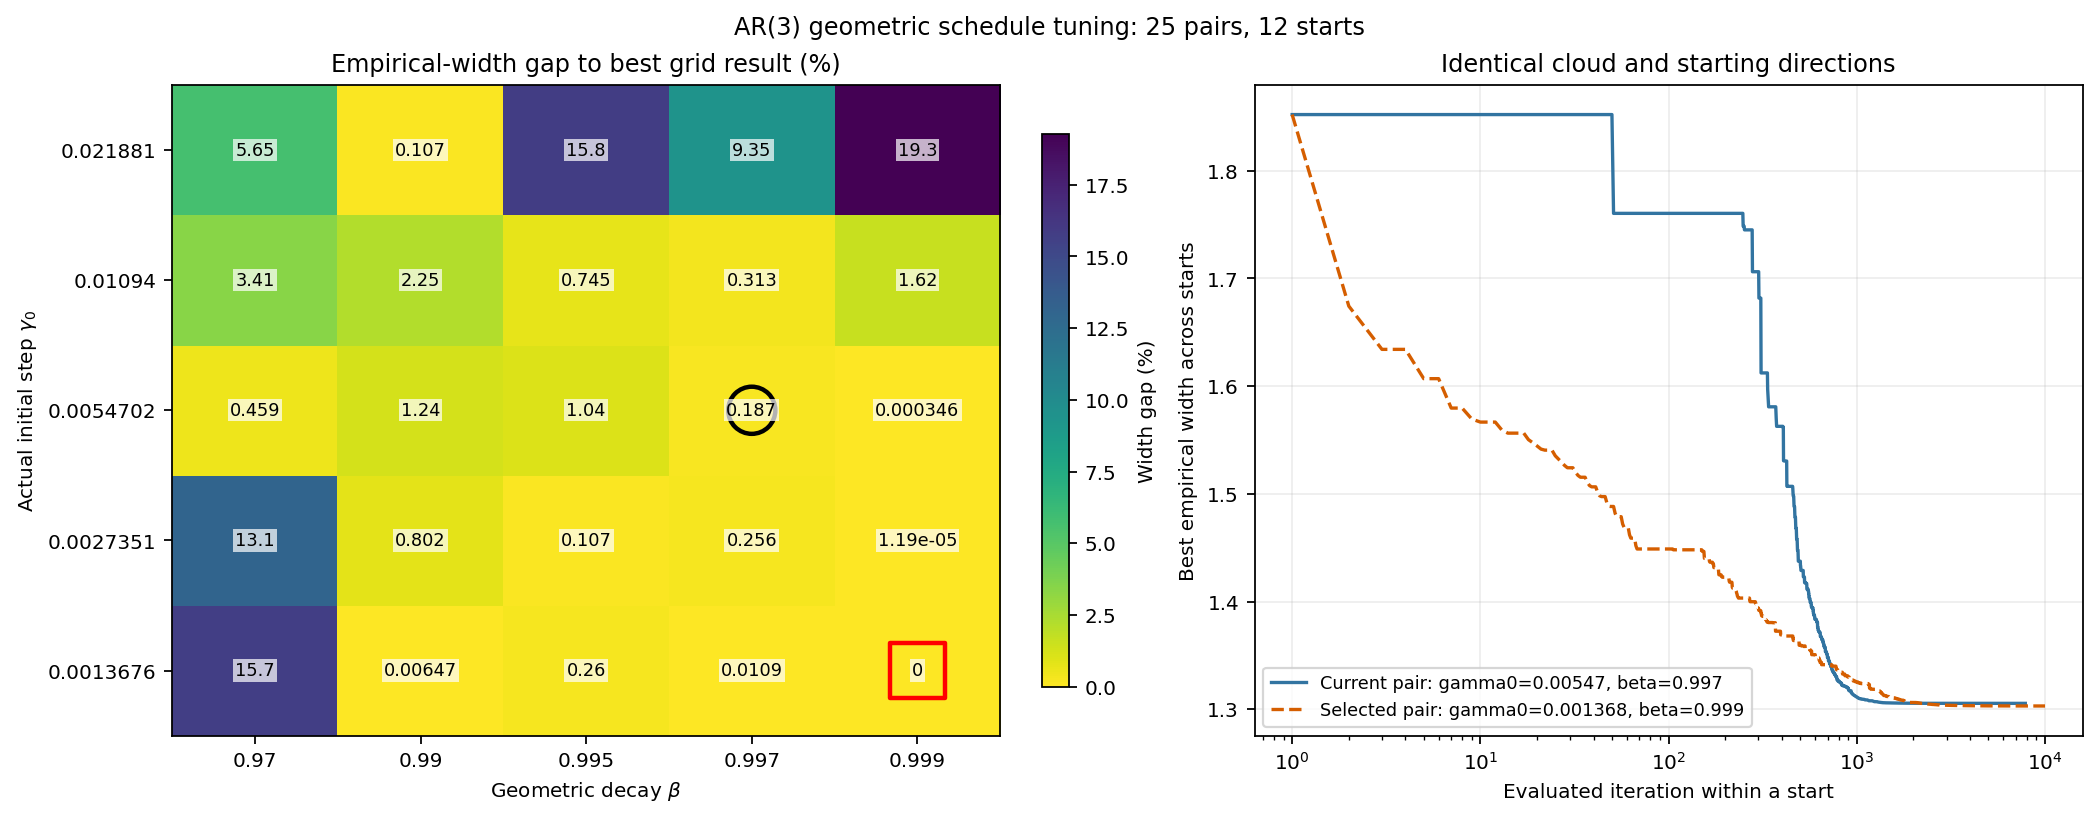

In [10]:
grid_widths = tuning_ranking.pivot(index="gamma0", columns="beta", values="minimum_width").reindex(
    index=tuning_gamma0_values, columns=tuning_beta_values,
)
width_gaps = 100.0 * (
    grid_widths.to_numpy() - tuned_schedule["minimum_width"]
) / max(tuned_schedule["minimum_width"], 1e-12)

with plt.rc_context({"font.size": 9, "pdf.fonttype": 42}):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
    image = axes[0].imshow(width_gaps, origin="lower", aspect="auto", cmap="viridis_r")
    axes[0].set_xticks(np.arange(len(tuning_beta_values)), [f"{value:g}" for value in tuning_beta_values])
    axes[0].set_yticks(np.arange(len(tuning_gamma0_values)), [f"{value:.5g}" for value in tuning_gamma0_values])
    axes[0].set(xlabel=r"Geometric decay $\beta$", ylabel=r"Actual initial step $\gamma_0$",
                title="Empirical-width gap to best grid result (%)")
    for row_index in range(len(tuning_gamma0_values)):
        for column_index in range(len(tuning_beta_values)):
            axes[0].text(column_index, row_index, f"{width_gaps[row_index, column_index]:.3g}",
                         ha="center", va="center", fontsize=8,
                         bbox={"facecolor": "white", "alpha": 0.7, "edgecolor": "none", "pad": 1})
    for schedule, marker, color, size in (
        (baseline_schedule, "o", "black", 450),
        (tuned_schedule, "s", "red", 600),
    ):
        axes[0].scatter(
            np.flatnonzero(tuning_beta_values == schedule["beta"])[0],
            np.flatnonzero(tuning_gamma0_values == schedule["gamma0"])[0],
            marker=marker, s=size, facecolors="none", edgecolors=color, linewidths=2,
        )
    fig.colorbar(image, ax=axes[0], shrink=0.85, label="Width gap (%)")
    for schedule, label, color, linestyle in (
        (baseline_schedule, "Current pair", "#3274A1", "-"),
        (tuned_schedule, "Selected pair", "#D55E00", "--"),
    ):
        history = tuning_result["histories"][schedule["candidate_id"]]
        axes[1].plot(np.arange(1, len(history) + 1), history, color=color, ls=linestyle,
                     label=f"{label}: gamma0={schedule['gamma0']:.4g}, beta={schedule['beta']:g}")
    axes[1].set(xlabel="Evaluated iteration within a start", ylabel="Best empirical width across starts",
                title="Identical cloud and starting directions", xscale="log")
    axes[1].ticklabel_format(axis="y", style="plain", useOffset=False)
    axes[1].grid(alpha=0.22)
    axes[1].legend(fontsize=8)
    fig.suptitle(f"AR({p}) geometric schedule tuning: {len(tuning_ranking)} pairs, {len(initial_directions)} starts")
    tuning_pdf_path = TUNING_PDF_DIR / "gamma0_beta_tuning.pdf"
    tuning_png_path = TUNING_IMAGE_DIR / "gamma0_beta_tuning.png"
    fig.savefig(tuning_pdf_path, bbox_inches="tight")
    fig.savefig(tuning_png_path, dpi=160, bbox_inches="tight")
    plt.close(fig)
print(f"Tuning PDF: {tuning_pdf_path}")
display(Image(filename=str(tuning_png_path)))
